# Assignment 2: Evaluating an energy consulting programme

**Group 5:** Glenvicia Sim, David Wolthuis, Balram Chakraborty

## Problem Statement
A government funds energy consulting to reduce plants' electricity use. However, improved efficiency may lower production costs and encourage plants to expand output and use more inputs, offsetting some of the initial energy savings through a rebound effect. This assignment evaluates the programme's effect on electricity use, examines the effect changes when labor becomes adjustable, and uses the production model to assess the implications of a further 20% efficiency improvement.
 
The analysis uses a **synthetic randomized pilot** of 480 plants observed monthly from month -3 through month 12. Half were assigned consulting beginning in month 1. Each plant's labor-adjustment month (4, 6, or 8) was scheduled independently before treatment assignment. Electricity is always adjustable.

The production model supplied with the assignment is $q=A\sqrt{\min\{L,\eta E\}}$, where $A$ is plant productivity, $L$ is labor, $E$ is electricity, and $\eta$ is electricity efficiency. The data do not directly observe $A$ or $\eta$; model-based claims therefore require explicit assumptions.

**Important:** plants, not plant-month observations, are the randomized units. The notebook estimates treatment effects on plant-level changes from month 0 and uses one observation per plant in each estimate. The synthetic series illustrates model counterfactuals; it is not a replication of a real experiment.

## Analysis plan and interpretation
This analysis argues that the electricity savings from energy consulting are likely to depend on plants' ability to adjust production: consulting may reduce electricity use in the short run, while later labor and output expansion may offset those savings through rebound. Using the synthetic randomized panel, the analysis assesses this claim by comparing plant-level changes from the final pre-treatment month between consulting and control plants, accounting for the sector-by-adjustment-month randomization strata and reporting HC2 standard errors. It also examines output, labor, reconstructed operating profit, and differences across labor-adjustment cohorts. Finally, the production model is used to illustrate how a further 20% efficiency improvement could affect electricity requirements under stated assumptions; this counterfactual does not identify the causal effect of a second consulting round.

All monetary values are in CU. Recorded-profit calculations exclude consulting-delivery costs and environmental damages.

## Assignment question tracker

Use this map to track the notebook against the assignment handout. `[x]` = substantially covered; `[~]` = partial; `[ ]` = not yet addressed. The assignment's core workload is Questions 1-8; Question 9 is optional.

| Assignment question | Related notebook section(s) | Status / follow-up |
|---|---|---|
| **Q1. Explore electricity use before and after consulting** | **Variable guide**; panel validation; **Plant assignment and baseline summaries**; raw group-means plot and **Graph analysis and conclusion** | [x] Data checks, baseline summaries and descriptive trends are included. |
| **Q2. What does the time pattern tell you?** | Raw group-means plot and interpretation; **Interpreting the dynamic treatment-effect plots**; **Electricity effect change with labor flexibility?** | [x] Time pattern and adjustment-cohort timing are discussed. |
| **Q3. Evaluate the programme** | **Estimating dynamic intent-to-treat effects**; effect tables and confidence-interval plots; period summary; combined interpretation | [~] Plant-level ITT effects, uncertainty and horizons are reported; explicitly distinguish the average plant response from the change in total electricity consumption. |
| **Q4. Use Unit 3 to make sense of the findings** | **Electricity effect change with labor flexibility?**; **Production model and the further-efficiency scenario** | [~] The rebound mechanism is introduced, but the full optimization by horizon, assumptions and economic diagrams still need to be developed. |
| **Q5. Can the initial response reveal the efficiency gain?** | No dedicated section currently | [ ] Add an estimate of the efficiency change from baseline and months 1-3, explain the identifying conditions, and check supporting outcomes and persistence. |
| **Q6. Does your explanation predict more than the initial pattern?** | Cohort analysis; reconstructed operating-profit estimates | [~] Some related results appear, but the required held-out predictions for months 9-12, quantitative production/electricity criterion, heterogeneity tests, input-relationship tests and alternative explanation are not yet covered. |
| **Q7. Evaluate a further efficiency improvement** | **Production model and the further-efficiency scenario**; efficiency-sensitivity table | [~] A stylized fixed-output electricity calculation is included; plant-level output, labor, electricity and profit counterfactuals under fixed and flexible labor, plus aggregate and across-plant comparisons, remain to be added. |
| **Q8. Brief the policymaker (200-300 words)** | **Conclusion and limitations** | [~] The conclusion summarizes findings, but it is not yet a 200-300 word policymaker briefing covering the proposed follow-up, recommendation, uncertainty and useful next test/data. |
| **Q9. Optional Cobb-Douglas comparison** | No dedicated section currently | [ ] Optional; add the comparison only if you choose to complete it. |

The status describes current notebook content, not a grade. In particular, the presence of a related plot or estimate does not mean every subpart of a question is complete.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The path works when this notebook is opened from the repository root or its subfolder.
candidate_paths = [Path("data/energy_firms.csv"), Path("../data/energy_firms.csv")]
data_path = next((path for path in candidate_paths if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError("Could not find data/energy_firms.csv. Open the notebook from the repository root or its data subfolder.")

df = pd.read_csv(data_path)
print(f"Loaded {data_path}: {len(df):,} rows")
display(df.head())

Loaded data/energy_firms.csv: 7,680 rows


,firm_id,sector,treated,month,adjust_month,labor_adjustable,output,labor,electricity,output_price,wage,energy_price
0,F001,Textiles,0,-3,4,1,100.239636,174.153124,4184.171250,7199.02915,1163.478189,36.693608
1,F001,Textiles,0,-2,4,1,99.011563,172.124961,4411.388868,7199.02915,1163.478189,36.693608
2,F001,Textiles,0,-1,4,1,102.154783,170.255851,4276.845098,7199.02915,1163.478189,36.693608
3,F001,Textiles,0,0,4,1,99.568497,172.706398,4446.593229,7199.02915,1163.478189,36.693608
4,F001,Textiles,0,1,4,0,99.699985,174.145341,4281.219976,7199.02915,1163.478189,36.693608


In [2]:
# Check the expected panel structure and assignment design.
required_columns = {
    "firm_id", "sector", "treated", "month", "adjust_month",
    "labor_adjustable", "output", "labor", "electricity",
    "output_price", "wage", "energy_price",
}
missing_columns = required_columns.difference(df.columns)
assert not missing_columns, f"Missing required columns: {sorted(missing_columns)}"
assert not df.duplicated(["firm_id", "month"]).any(), "firm_id + month must uniquely identify observations"
assert df.isna().sum().sum() == 0, "Unexpected missing values found"

plant = df.groupby("firm_id").agg(
    treated_count=("treated", "nunique"),
    sector_count=("sector", "nunique"),
    adjustment_month_count=("adjust_month", "nunique"),
    months_observed=("month", "nunique"),
)
assert plant[["treated_count", "sector_count", "adjustment_month_count"]].eq(1).all().all(), "Plant-level assignment fields should be constant"
assert plant["months_observed"].eq(16).all(), "Each plant should have 16 monthly observations"

print(f"Plants: {df['firm_id'].nunique()}; observations: {len(df):,}")
print(f"Months: {df['month'].min()} to {df['month'].max()}")
print(f"Treated plants: {df.drop_duplicates('firm_id')['treated'].sum():.0f} / {len(plant)}")
print("Adjustment-month counts (plants):")
display(df.drop_duplicates("firm_id")["adjust_month"].value_counts().sort_index().rename("plants").to_frame())
print("Treatment counts within randomization strata:")
display(pd.crosstab([df.drop_duplicates("firm_id")["sector"], df.drop_duplicates("firm_id")["adjust_month"]], df.drop_duplicates("firm_id")["treated"]))

Plants: 480; observations: 7,680
Months: -3 to 12
Treated plants: 240 / 480
Adjustment-month counts (plants):


,plants
adjust_month,
4,160
6,160
8,160


Treatment counts within randomization strata:


treated                  0   1
sector    adjust_month        
Chemicals 4             40  40
          6             40  40
          8             40  40
Textiles  4             40  40
          6             40  40
          8             40  40

## Variable guide
- `firm_id`: persistent plant identifier; the unit of random assignment.
- `treated`: assignment to consulting (1) or control (0), constant for a plant.
- `month`: monthly panel period, from -3 through 12; consulting starts in month 1.
- `adjust_month`: scheduled month (4, 6, or 8) when labor first becomes freely adjustable.
- `labor_adjustable`: indicator for whether labor is freely adjustable in that month.
- `output`, `labor`, `electricity`: standardized monthly physical quantities; labor is in blocks of 100 worker-hours and electricity in MWh.
- `output_price`, `wage`, `energy_price`: plant-specific prices, constant over time and not changed by consulting. Wage is per 100-hour labor block.

The dataset documentation states that quantities have small independent multiplicative recording errors and that no exits, spillovers, inventories, product-quality changes, or other variable inputs are included.

In [3]:
# One row per plant for assignment and baseline summaries.
plants = df.drop_duplicates("firm_id").copy()
print("Plant assignment summary:")
display(plants.groupby("treated").agg(
    plants=("firm_id", "nunique"),
    adjustment_month_mean=("adjust_month", "mean"),
).rename(index={0: "Control", 1: "Consulting"}))

baseline = df.loc[df["month"].between(-3, 0)]
baseline_summary = baseline.groupby("treated")[
    ["output", "labor", "electricity"]
].mean().rename(index={0: "Control", 1: "Consulting"})
print("Mean outcomes during baseline months (-3 to 0):")
display(baseline_summary.round(2))
print("Baseline consulting minus control (descriptive, not a treatment effect):")
display((baseline_summary.loc["Consulting"] - baseline_summary.loc["Control"]).rename("difference").to_frame().round(2))

Plant assignment summary:


,plants,adjustment_month_mean
treated,,
Control,240,6.0
Consulting,240,6.0


Mean outcomes during baseline months (-3 to 0):


,output,labor,electricity
treated,,,
Control,76.60,161.89,4108.71
Consulting,80.87,174.58,4413.71


Baseline consulting minus control (descriptive, not a treatment effect):


,difference
output,4.28
labor,12.69
electricity,305.00


The baseline comparison is a balance description only. In a finite randomized sample, the groups can differ before treatment, particularly because plants differ persistently in scale, prices, and productivity. The estimates below subtract each plant's own month-0 outcome and compare those changes across treatment groups within the assignment strata.

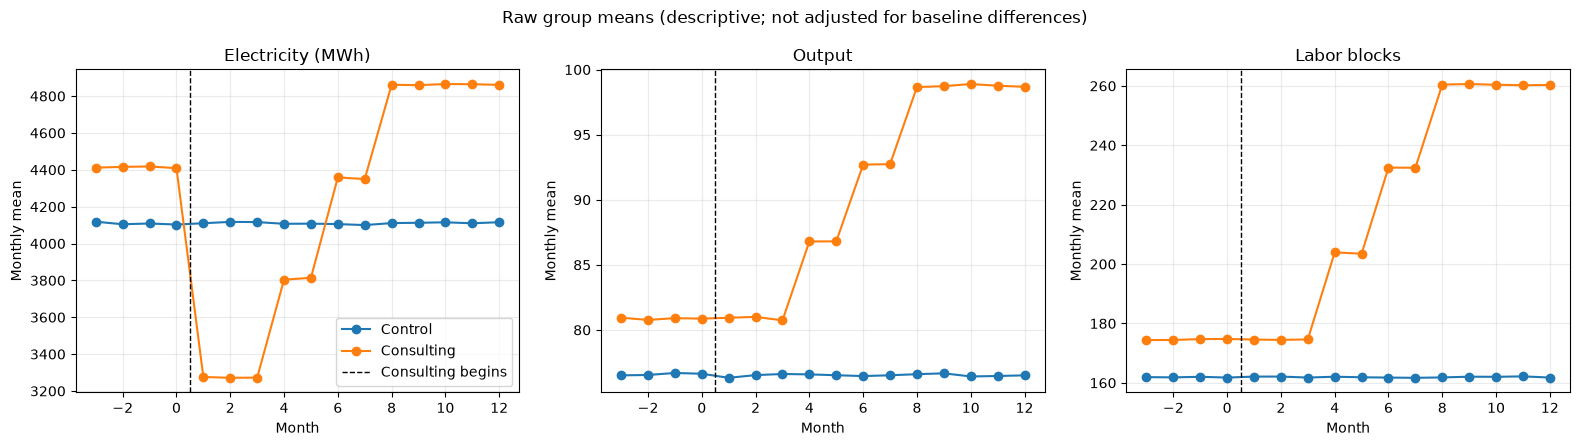

In [4]:
monthly_means = df.groupby(["month", "treated"])[["electricity", "output", "labor"]].mean().reset_index()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, outcome, label in zip(axes, ["electricity", "output", "labor"], ["Electricity (MWh)", "Output", "Labor blocks"]):
    for treatment, group in monthly_means.groupby("treated"):
        ax.plot(group["month"], group[outcome], marker="o", label="Consulting" if treatment else "Control")
    ax.axvline(0.5, color="black", linestyle="--", linewidth=1, label="Consulting begins" if outcome == "electricity" else None)
    ax.set(title=label, xlabel="Month", ylabel="Monthly mean")
    ax.grid(alpha=0.25)
axes[0].legend()
fig.suptitle("Raw group means (descriptive; not adjusted for baseline differences)")
fig.tight_layout()
plt.show()

## Graph analysis and conclusion

### Graph analysis
The figure compares raw monthly averages for consulting-assigned and control plants. Before consulting begins, the consulting group already has higher average electricity use (about 300 MWh per plant-month), as well as slightly higher output and labor. This baseline gap is important: the lines are not directly comparable as treatment effects.

After consulting begins in month 1, average electricity use among consulting plants falls sharply in months 1-3, then begins rising in month 4. It remains below the control average through month 5, moves above control in month 6, and stays higher through month 12. Output and labor also rise from month 4, with further increases around months 6 and 8. These steps coincide with the scheduled months when labor becomes adjustable for different plant cohorts. The later increases in electricity alongside output and labor are consistent with a possible rebound as production expands.

### Conclusion
Descriptively, the graph suggests an early reduction in electricity use followed by a later increase as labor and output expand. However, it plots raw group means, and the groups differ before treatment; therefore, neither the apparent early reduction nor the later increase should be interpreted on its own as the causal effect of consulting. Use the subsequent plant-level analysis, which accounts for baseline changes and the assignment to assess treatment effects. The visual pattern is consistent with rebound, but does not by itself establish that labor flexibility caused the later increase.

## Estimating dynamic intent-to-treat effects
For each outcome and month $t$, the estimate is the coefficient on treatment in a plant-level regression of $Y_{it}-Y_{i0}$ on treatment and randomization-stratum fixed effects. The coefficient is therefore a difference-in-differences relative to month 0. Month 0 is the final pre-intervention month.

Each regression has one row per plant, so repeated monthly records are not treated as independent assignments. HC2 standard errors account for heteroskedasticity across plants. Effects are ITT effects of assignment; consulting uptake or a plant's realized efficiency gain is not separately observed.

In [5]:
outcomes = ["electricity", "output", "labor"]
df["stratum"] = df["sector"].astype(str) + " | adjustment month " + df["adjust_month"].astype(str)

def estimate_dynamic_effects(data, outcome, adjustment_month=None):
    """Estimate treatment effects on change from month 0, with HC2 SEs."""
    subset = data if adjustment_month is None else data.loc[data["adjust_month"].eq(adjustment_month)]
    wide = subset.pivot(index="firm_id", columns="month", values=outcome)
    if 0 not in wide.columns:
        raise ValueError("Month 0 is required as the baseline")
    assignment = subset.drop_duplicates("firm_id").set_index("firm_id")[["treated", "stratum"]]
    rows = []
    for month in sorted(wide.columns):
        if month == 0:
            continue
        analysis = assignment.join((wide[month] - wide[0]).rename("change")).dropna()
        stratum_dummies = pd.get_dummies(analysis["stratum"], drop_first=True, dtype=float)
        design = pd.concat(
            [
                pd.Series(1.0, index=analysis.index, name="intercept"),
                analysis["treated"].astype(float),
                stratum_dummies,
            ],
            axis=1,
        )
        x = design.to_numpy(dtype=float)
        y = analysis["change"].to_numpy(dtype=float)
        bread = np.linalg.inv(x.T @ x)
        coefficients = bread @ x.T @ y
        residuals = y - x @ coefficients
        leverage = np.einsum("ij,jk,ik->i", x, bread, x)
        hc2_weights = residuals**2 / (1 - leverage)
        meat = x.T @ (hc2_weights[:, None] * x)
        covariance = bread @ meat @ bread
        treatment_index = design.columns.get_loc("treated")
        estimate = coefficients[treatment_index]
        std_error = np.sqrt(covariance[treatment_index, treatment_index])
        rows.append({
            "month": month,
            "estimate": estimate,
            "std_error": std_error,
            "ci_low": estimate - 1.96 * std_error,
            "ci_high": estimate + 1.96 * std_error,
            "plants": len(analysis),
        })
    return pd.DataFrame(rows)

In [6]:
effects = {
    outcome: estimate_dynamic_effects(df, outcome)
    for outcome in outcomes
}
electricity_effects = effects["electricity"]
print("Dynamic electricity ITT estimates: treatment effect on change from month 0")
display(electricity_effects.round(2))
print("Dynamic output ITT estimates:")
display(effects["output"].round(2))
print("Dynamic labor ITT estimates:")
display(effects["labor"].round(2))

Dynamic electricity ITT estimates: treatment effect on change from month 0


,month,estimate,std_error,ci_low,ci_high,plants
0,-3,-12.39,12.58,-37.06,12.28,480
1,-2,5.49,11.78,-17.59,28.57,480
2,-1,3.69,12.06,-19.95,27.34,480
3,1,-1139.86,40.44,-1219.12,-1060.61,480
4,2,-1151.84,41.05,-1232.30,-1071.37,480
5,3,-1149.68,39.72,-1227.54,-1071.83,480
6,4,-609.08,51.56,-710.15,-508.01,480
7,5,-599.71,51.08,-699.82,-499.60,480
8,6,-52.75,50.54,-151.80,46.30,480
9,7,-55.96,49.92,-153.80,41.87,480


Dynamic output ITT estimates:


,month,estimate,std_error,ci_low,ci_high,plants
0,-3,0.20,0.19,-0.18,0.57,480
1,-2,-0.00,0.18,-0.37,0.36,480
2,-1,-0.02,0.20,-0.41,0.37,480
3,1,0.38,0.20,-0.01,0.77,480
4,2,0.24,0.21,-0.16,0.64,480
5,3,-0.11,0.19,-0.48,0.26,480
6,4,5.98,0.53,4.93,7.03,480
7,5,6.05,0.53,5.01,7.09,480
8,6,12.01,0.63,10.78,13.24,480
9,7,11.98,0.61,10.78,13.19,480


Dynamic labor ITT estimates:


,month,estimate,std_error,ci_low,ci_high,plants
0,-3,-0.54,0.30,-1.13,0.06,480
1,-2,-0.40,0.32,-1.03,0.22,480
2,-1,-0.32,0.32,-0.94,0.30,480
3,1,-0.53,0.32,-1.16,0.11,480
4,2,-0.66,0.33,-1.31,-0.01,480
5,3,-0.16,0.33,-0.81,0.49,480
6,4,28.87,2.56,23.87,33.88,480
7,5,28.61,2.53,23.65,33.56,480
8,6,57.72,3.14,51.57,63.86,480
9,7,57.72,3.16,51.53,63.92,480


## Combined interpretation of the dynamic ITT estimates

Taken together, the estimates show a sharp early reduction in electricity use: in months 1-3, consulting assignment reduced use by about **1,147 MWh per plant-month** relative to control. Output and labor estimates are close to zero in this early period, with most confidence intervals including zero. As labor becomes adjustable for scheduled cohorts in months 4, 6, and 8, the estimated effects on output and labor rise in steps. By months 8-12, their average monthly estimates are about **+18 standardized output batches** and **+85 labor blocks** (each block is 100 worker-hours) per plant relative to control.

Meanwhile, the electricity reduction shrinks to about **54 MWh** in months 6-7, with confidence intervals that include zero, then reverses to an increase of about **444 MWh per plant-month** in months 8-12; the individual monthly 95% confidence intervals in this late period are above zero. Higher output and labor alongside the late electricity increase are consistent with a rebound pattern: expanded production may offset the initial energy savings. They do not, by themselves, prove that labor flexibility caused the reversal.

These are intent-to-treat estimates from the synthetic 480-plant dataset, comparing plant-level changes from month 0 and adjusting for sector-by-scheduled-adjustment-month strata. Standard errors use HC2. Interpret period figures as averages of the monthly point estimates, not as separately tested period-level effects.

In [11]:
# Summarize the month-specific estimates over broad calendar-time windows.
# These are averages of dynamic ITT coefficients, not separate treatment assignments.
periods = {
    "Early response (months 1-3)": [1, 2, 3],
    "Adjustment transition (months 4-5)": [4, 5],
    "Later response (months 8-12)": [8, 9, 10, 11, 12],
}
period_rows = []
for outcome, result in effects.items():
    for period, months in periods.items():
        selected = result.loc[result["month"].isin(months), "estimate"]
        period_rows.append({"outcome": outcome, "period": period, "mean_monthly_ITT": selected.mean()})
period_summary = pd.DataFrame(period_rows).pivot(index="period", columns="outcome", values="mean_monthly_ITT")
print("Average of monthly ITT estimates within each descriptive calendar-time window:")
display(period_summary.round(2))

Average of monthly ITT estimates within each descriptive calendar-time window:


outcome,electricity,labor,output
period,,,
Adjustment transition (months 4-5),-604.40,28.74,6.01
Early response (months 1-3),-1147.13,-0.45,0.17
Later response (months 8-12),443.60,85.42,17.98


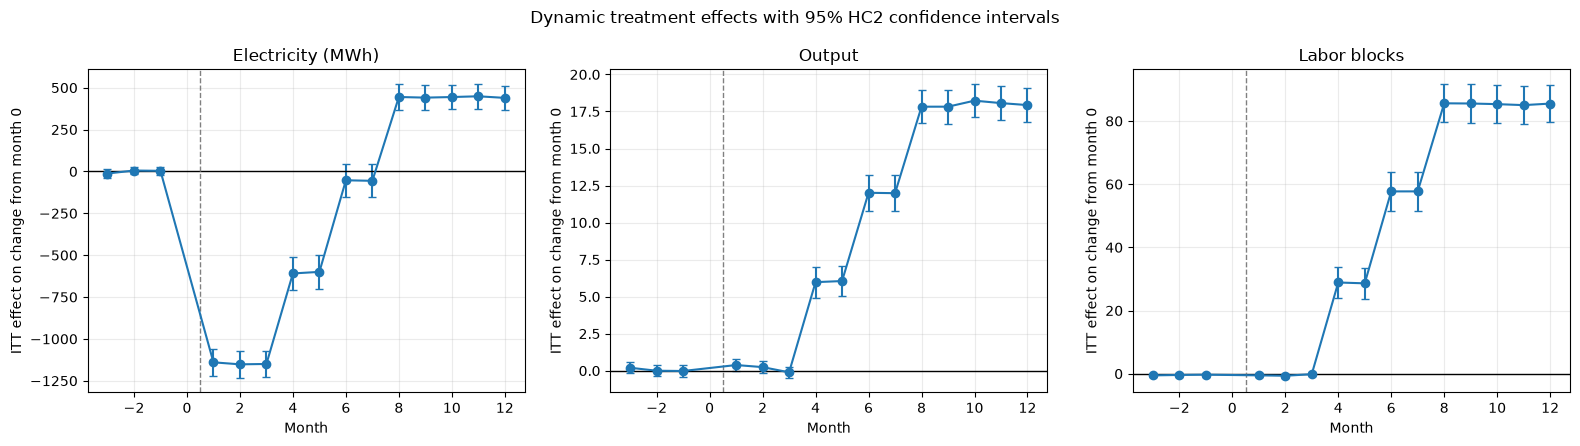

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
labels = {"electricity": "Electricity (MWh)", "output": "Output", "labor": "Labor blocks"}
for ax, outcome in zip(axes, outcomes):
    result = effects[outcome]
    ax.errorbar(
        result["month"], result["estimate"],
        yerr=[result["estimate"] - result["ci_low"], result["ci_high"] - result["estimate"]],
        fmt="o-", capsize=3,
    )
    ax.axhline(0, color="black", linewidth=1)
    ax.axvline(0.5, color="gray", linestyle="--", linewidth=1)
    ax.set(title=labels[outcome], xlabel="Month", ylabel="ITT effect on change from month 0")
    ax.grid(alpha=0.25)
fig.suptitle("Dynamic treatment effects with 95% HC2 confidence intervals")
fig.tight_layout()
plt.show()

## Interpreting the dynamic treatment-effect plots

### What the plots show
The vertical axis is the estimated intent-to-treat (ITT) effect on each outcome's change from month 0, relative to control. The horizontal zero line indicates no estimated treatment effect; the dashed line marks consulting's start. Error bars are 95% HC2 confidence intervals: when an interval crosses zero, that month's estimate is not statistically distinguishable from zero at the 5% level.

- **Electricity:** Consulting assignment reduced use by about **1,147 MWh per plant-month on average in months 1-3**; each monthly confidence interval is below zero. The reduction shrinks to about **604 MWh in months 4-5**. Estimates in months 6-7 are close to zero and their intervals cross zero. In months 8-12, the estimated effect reverses to about **+444 MWh per plant-month**, with monthly intervals above zero.
- **Output:** Effects are near zero in months 1-3, then rise as labor becomes adjustable: approximately **+6 batches** in months 4-5, **+12** in months 6-7, and **+18 batches per plant-month** in months 8-12. The later monthly confidence intervals are above zero.
- **Labor:** Effects are near zero in months 1-3, then rise to about **+29 labor blocks** in months 4-5, **+58 blocks** in months 6-7, and **+85 blocks per plant-month** in months 8-12. A labor block represents 100 worker-hours; the estimates from month 4 onward have confidence intervals above zero.

### Conclusion
Across the three outcomes, the pattern is consistent with an initial energy-saving response followed by increased production: electricity use falls early, while output and labor increase in steps around the scheduled labor-adjustment months. By months 8-12, electricity use is estimated to be above its month-0-relative control change at the same time as output and labor are higher. This is consistent with a rebound effect, in which production expansion offsets initial energy savings, but the plots alone do not establish that labor flexibility caused the reversal.

These are plant-level ITT estimates from the **synthetic 480-plant dataset**, adjusted for sector-by-adjustment-month assignment strata. They estimate effects of assignment, not effects of actual consulting uptake, and the monthly intervals are pointwise rather than a joint test across months.

## Electricity effect change with labor flexibility?
Plants have different scheduled adjustment months. To avoid interpreting the pooled calendar-time pattern as if every plant became flexible at the same time, the next cell estimates the same month-0 change contrast separately for each adjustment-month cohort. The cohort schedule was set before random assignment, but these subgroup estimates can be less precise because each cohort is smaller.

adjust_month,4,6,8
month,,,
-3,-21.5,-13.5,-2.2
-2,7.6,25.0,-16.2
-1,-1.0,11.5,0.5
1,-1195.7,-1114.1,-1109.8
2,-1188.1,-1147.5,-1119.9
3,-1200.2,-1138.2,-1110.6
4,414.6,-1119.5,-1122.3
5,416.1,-1126.9,-1088.4
6,425.0,512.9,-1096.2


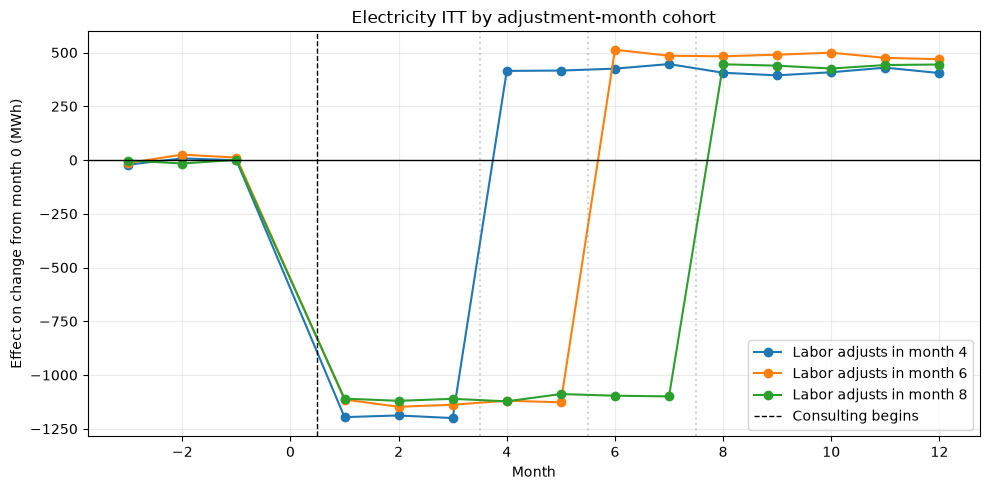

In [13]:
cohort_effects = pd.concat(
    [
        estimate_dynamic_effects(df, "electricity", adjustment_month=adjust_month).assign(adjust_month=adjust_month)
        for adjust_month in sorted(df["adjust_month"].unique())
    ],
    ignore_index=True,
)
display(cohort_effects.pivot(index="month", columns="adjust_month", values="estimate").round(1))

fig, ax = plt.subplots(figsize=(10, 5))
for adjust_month, group in cohort_effects.groupby("adjust_month"):
    ax.plot(group["month"], group["estimate"], marker="o", label=f"Labor adjusts in month {adjust_month}")
    ax.axvline(adjust_month - 0.5, color="gray", linestyle=":", alpha=0.35)
ax.axhline(0, color="black", linewidth=1)
ax.axvline(0.5, color="black", linestyle="--", linewidth=1, label="Consulting begins")
ax.set(title="Electricity ITT by adjustment-month cohort", xlabel="Month", ylabel="Effect on change from month 0 (MWh)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Interpreting the plots
The raw-trend plots show observed group averages. Treated plants start with higher average levels, so the visible treated-control gap before consulting is a baseline difference—not a programme effect. After month 1, treated plants' electricity falls while labor is still constrained; later, output and labor rise and electricity use recovers. This pattern is consistent with energy savings followed by a rebound, but raw averages alone do not adjust for baseline differences.

The dynamic-effect plots address that issue by showing estimated treatment effects on changes from month 0, with 95% HC2 confidence intervals. For electricity, the estimated effect is strongly negative in months 1-3 (about -1,147 MWh per plant-month on average), smaller in months 4-5 (about -604 MWh), close to zero in months 6-7, and positive in months 8-12 (about +444 MWh). The month 0.5 dashed line marks the start of consulting. The confidence intervals are below zero in the early period and above zero in the late period, indicating that those estimated effects differ from zero under this model. Pre-treatment estimates are near zero, which is reassuring but does not prove every causal assumption.

The cohort plot separates the electricity estimates by scheduled labor-adjustment month. In each cohort, the effect is initially negative; it turns positive around that cohort's adjustment date: approximately month 4 for the month-4 cohort, month 6 for the month-6 cohort, and month 8 for the month-8 cohort. That timing is consistent with labor flexibility allowing plants to expand production and rebound. The plotted cohort estimates do not include confidence intervals, however, and labor flexibility itself was not randomized as a separate treatment. Interpret this as suggestive timing evidence, not definitive proof that flexibility alone causes the reversal.

In [14]:
# Reconstructed operating profit from recorded quantities and prices.
# Wage is per block of 100 worker-hours as documented in the data dictionary.
df["revenue"] = df["output_price"] * df["output"]
df["labor_cost"] = df["wage"] * df["labor"]
df["electricity_cost"] = df["energy_price"] * df["electricity"]
df["operating_profit"] = df["revenue"] - df["labor_cost"] - df["electricity_cost"]

profit_effects = estimate_dynamic_effects(df, "operating_profit")
print("Effect on reconstructed operating profit (CU/month), relative to month 0:")
display(profit_effects.round(2))
print("This is not full social surplus: consulting-delivery costs and environmental damages are unavailable.")

Effect on reconstructed operating profit (CU/month), relative to month 0:


,month,estimate,std_error,ci_low,ci_high,plants
0,-3,7438.71,5798.60,-3926.54,18803.96,480
1,-2,-145.28,5309.70,-10552.30,10261.74,480
2,-1,-385.04,5899.77,-11948.59,11178.50,480
3,1,191597.50,12155.73,167772.28,215422.72,480
4,2,186626.18,11351.34,164377.56,208874.81,480
5,3,180353.47,11137.52,158523.94,202183.00,480
6,4,196156.49,12324.80,171999.89,220313.09,480
7,5,199905.68,13148.90,174133.83,225677.54,480
8,6,215623.00,13884.16,188410.06,242835.95,480
9,7,217902.83,14533.37,189417.43,246388.23,480


This is not full social surplus: consulting-delivery costs and environmental damages are unavailable.


## Production model and the further-efficiency scenario
The assignment's Leontief production function is $q=A\sqrt{\min\{L,\eta E\}}$. If electricity is the binding input and output is held fixed, maintaining the same output requires $\eta E$ to stay constant. A 20% increase in $\eta$ therefore changes required electricity to $E/1.2$, a **16.7% reduction**, not 20%.

That calculation is conditional on fixed output and the electricity input being binding. If output expands, required electricity under this simplified binding-input calculation scales with $q^2/\eta$. Actual plant choices also depend on prices, labor flexibility, productivity, and whether electricity remains binding. Since the dataset does not observe $A$, $\eta$, or an assigned second consulting round, it cannot by itself identify the causal effect of a second round. The next cell reports a sensitivity scenario rather than claiming a structural estimate.

In [15]:
efficiency_gain = 0.20
efficiency_ratio = 1 + efficiency_gain
output_growth = np.array([0.00, 0.05, 0.10, 0.20])
scenario = pd.DataFrame({"output_growth": output_growth})
scenario["energy_requirement_ratio"] = (1 + scenario["output_growth"]) ** 2 / efficiency_ratio
scenario["energy_change_percent"] = 100 * (scenario["energy_requirement_ratio"] - 1)
print("Stylized electricity requirement under a 20% efficiency gain (electricity binding):")
display(scenario.assign(output_growth=lambda x: 100 * x["output_growth"]).rename(columns={"output_growth": "output_growth_percent"}).round(2))
break_even_output_growth = np.sqrt(efficiency_ratio) - 1
print(f"Output growth that exactly offsets the efficiency gain in this scenario: {break_even_output_growth:.1%}")

Stylized electricity requirement under a 20% efficiency gain (electricity binding):


,output_growth_percent,energy_requirement_ratio,energy_change_percent
0,0.0,0.83,-16.67
1,5.0,0.92,-8.12
2,10.0,1.01,0.83
3,20.0,1.20,20.00


Output growth that exactly offsets the efficiency gain in this scenario: 9.5%


## Conclusion and limitations
In this synthetic dataset, the stratified difference-in-differences estimates show a large early electricity reduction: averaging months 1-3, assignment to consulting reduced electricity use by about **1,147 MWh per plant-month** relative to month 0 (the individual monthly 95% confidence intervals are below zero). The estimated reduction shrinks during months 4-5 to about **604 MWh**. In months 8-12, the estimated effect is instead an increase of about **444 MWh per plant-month** (individual monthly 95% confidence intervals are above zero). These are changes relative to month 0, not raw comparisons between treated and control means.

In the later window, the estimated treatment effects also include about **18 additional output batches** and **85 additional labor blocks per month**. Rising output and labor alongside rising electricity is consistent with a rebound interpretation. The adjustment-cohort estimates help locate the timing, but the observed pattern alone does not establish that labor flexibility is the sole cause.

The 20% efficiency scenario predicts a 16.7% electricity reduction only at fixed output when electricity is binding. Output expansion can offset that saving; under the simplified $q^2/\eta$ relationship, about 9.5% output growth fully offsets it. A second round should therefore not be assumed to generate a fixed additional saving. Its net effect depends on remaining efficiency opportunities and production responses, and cannot be causally measured from this one-round assignment.

### Limitations
- The data are synthetic and designed to illustrate model counterfactuals, not to reproduce an actual programme evaluation.
- Treatment is randomized, but realized consulting uptake or the efficiency dose is not observed; estimates are intent-to-treat.
- Baseline outcomes differ by chance; all dynamic effects are relative to month 0 and adjust for sector × adjustment-month strata.
- The production model's productivity and efficiency parameters are unobserved, and standardized units make technological indices unit-dependent.
- Reconstructed operating profit contains quantity measurement error and excludes consulting costs and environmental damages.
- There is no second-round treatment arm, so the further-efficiency calculation is a model-based sensitivity scenario, not a second-round causal estimate.